In [6]:
# importing necessary libraries
import os
import sys
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score


In [7]:
# read data
df_X_test = pd.read_csv('X_test.csv')
df_X_train = pd.read_csv('X_train.csv')
df_y_train = pd.read_csv('y_train.csv')


In [10]:
import numpy as np
import pandas as pd

def normalize(df, method="zscore", axis=None):
    df = df.select_dtypes("number").astype(float)
    A = df.to_numpy()
    kw = dict(axis=axis, keepdims=True)

    if method == "minmax":
        lo, hi = np.nanmin(A, **kw), np.nanmax(A, **kw)
        out = (A - lo) / np.where(hi - lo == 0, 1, hi - lo)
    elif method == "zscore":
        sd = np.nanstd(A, **kw)
        out = (A - np.nanmean(A, **kw)) / np.where(sd == 0, 1, sd)
    elif method == "robust":
        q1, med, q3 = (np.nanpercentile(A, q, **kw) for q in (25, 50, 75))
        out = (A - med) / np.where(q3 - q1 == 0, 1, q3 - q1)
    elif method == "log":
        out = np.log1p(A)
    else:
        raise ValueError(method)

    return pd.DataFrame(out, index=df.index, columns=df.columns)

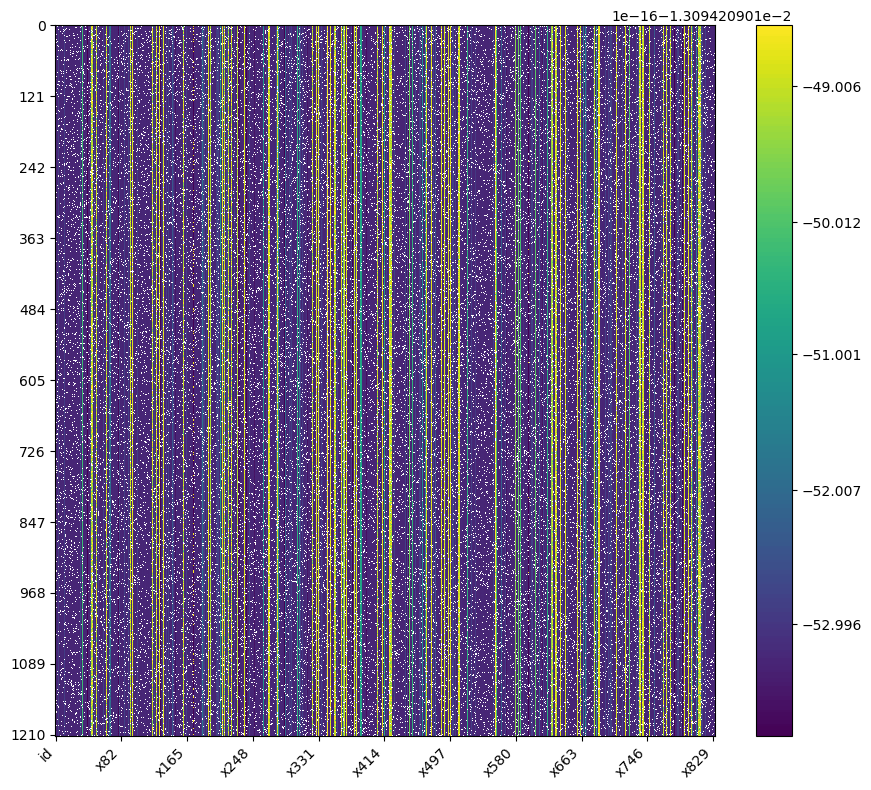

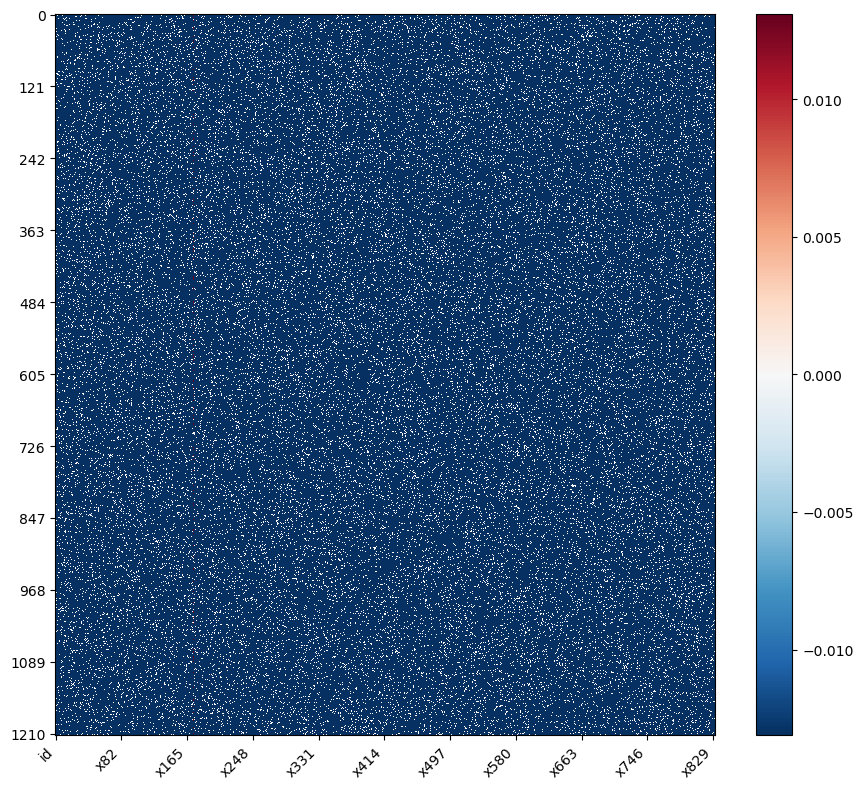

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def plot_df(df, cmap="viridis", robust=True, center=None, figsize=(9, 8)):
    A = df.to_numpy(dtype=float)

    # clip color range to 1st-99th percentile so outliers don't wash out the plot
    vmin, vmax = np.nanpercentile(A, [1, 99]) if robust else (np.nanmin(A), np.nanmax(A))
    if center is not None:                       # e.g. center=0 for correlation matrices
        a = max(abs(vmin - center), abs(vmax - center))
        vmin, vmax = center - a, center + a

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(A, cmap=cmap, vmin=vmin, vmax=vmax,
                   aspect="auto", interpolation="nearest")
    fig.colorbar(im, ax=ax)

    # with 1000 labels, show only ~10 ticks per axis
    step_r, step_c = max(1, len(df) // 10), max(1, df.shape[1] // 10)
    ax.set_yticks(range(0, len(df), step_r))
    ax.set_yticklabels(df.index[::step_r])
    ax.set_xticks(range(0, df.shape[1], step_c))
    ax.set_xticklabels(df.columns[::step_c], rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

dfn = normalize(df_X_train)
plot_df(dfn)                                   # general
plot_df(dfn, cmap="RdBu_r", center=0)          # correlation / signed data


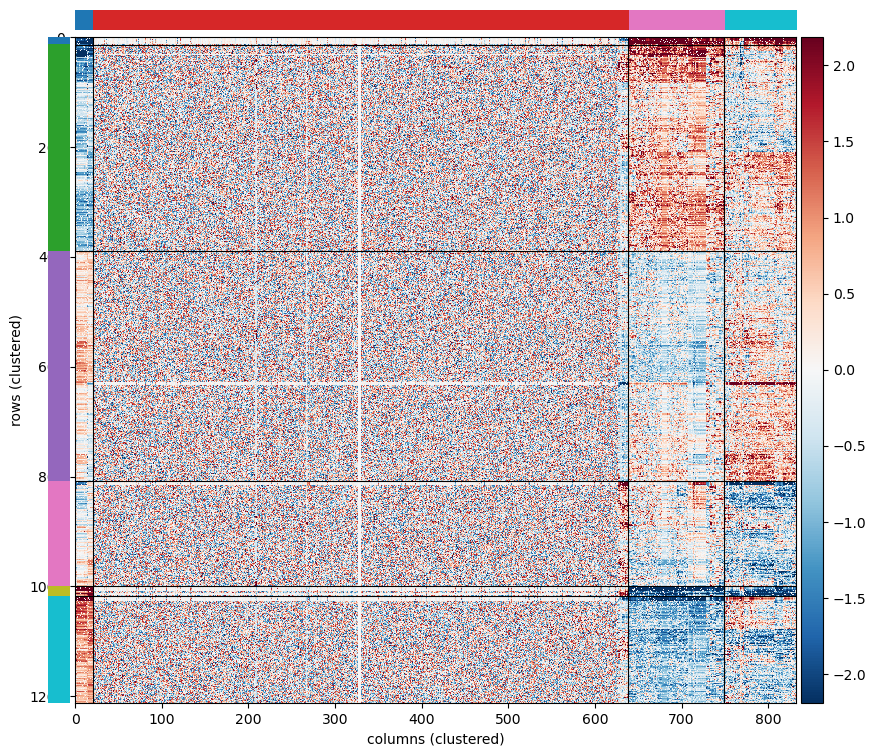

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list

def cluster_axis(X, k, method="ward", metric="euclidean"):
    """Return (leaf order, cluster label per item in the ORIGINAL order)."""
    Z = linkage(X, method=method, metric=metric)   # ward requires euclidean
    return leaves_list(Z), fcluster(Z, k, criterion="maxclust")

def plot_clusters(df, k_rows=5, k_cols=5, method="ward", metric="euclidean",
                  cmap="RdBu_r", center=0, symmetric=False, figsize=(10, 9)):
    A = df.to_numpy(dtype=float)
    A = np.nan_to_num(A)                            # linkage can't handle NaN

    r_order, r_lab = cluster_axis(A, k_rows, method, metric)
    if symmetric:                                   # square matrix (e.g. correlations):
        c_order, c_lab = r_order, r_lab             # same order on both axes
    else:
        c_order, c_lab = cluster_axis(A.T, k_cols, method, metric)

    B = A[np.ix_(r_order, c_order)]                 # reordered matrix
    rl, cl = r_lab[r_order], c_lab[c_order]         # labels in new order

    # colour range
    vmin, vmax = np.percentile(B, [1, 99])
    if center is not None:
        a = max(abs(vmin - center), abs(vmax - center))
        vmin, vmax = center - a, center + a

    # layout: heatmap + colour strips for row/col cluster membership
    fig = plt.figure(figsize=figsize)
    gs = GridSpec(2, 3, width_ratios=[0.03, 1, 0.03], height_ratios=[0.03, 1],
                  wspace=0.02, hspace=0.02)
    ax  = fig.add_subplot(gs[1, 1])
    axr = fig.add_subplot(gs[1, 0], sharey=ax)
    axc = fig.add_subplot(gs[0, 1], sharex=ax)
    cax = fig.add_subplot(gs[1, 2])

    im = ax.imshow(B, cmap=cmap, vmin=vmin, vmax=vmax,
                   aspect="auto", interpolation="nearest")
    fig.colorbar(im, cax=cax)

    # cluster strips
    axr.imshow(rl[:, None], aspect="auto", cmap="tab10", interpolation="nearest")
    axc.imshow(cl[None, :], aspect="auto", cmap="tab10", interpolation="nearest")
    for a_ in (axr, axc):
        a_.axis("off")

    # boundary lines where the cluster label changes
    for i in np.flatnonzero(np.diff(rl)) + 0.5:
        ax.axhline(i, color="k", lw=0.8)
    for j in np.flatnonzero(np.diff(cl)) + 0.5:
        ax.axvline(j, color="k", lw=0.8)

    ax.set_xlabel("columns (clustered)")
    ax.set_ylabel("rows (clustered)")
    plt.show()

    # reordered DataFrame + labels, for further analysis
    out = df.iloc[r_order, c_order]
    return out, pd.Series(r_lab, index=df.index, name="row_cluster"), \
                pd.Series(c_lab, index=df.columns, name="col_cluster")

# normalised df from the previous step
dfn = normalize(df_X_train, "zscore", axis=0)
df_sorted, row_clusters, col_clusters = plot_clusters(dfn, k_rows=6, k_cols=4)

# square, symmetric matrix (correlation / distance):
# plot_clusters(df.corr(), k_rows=6, symmetric=True, method="average", metric="correlation")